In [1]:
import pandas as pd
# (1)
# 1. Завантаження датасета
df = pd.read_csv("phishing_features.csv")

# 2. Назви колонок та розмір датасета
print("Назви колонок:", df.columns.tolist())
print("\nРозмір датасета:", df.shape)

Назви колонок: ['url', 'label', 'url_length', 'num_dots', 'has_https', 'has_ip', 'num_subdirs', 'num_params', 'suspicious_words', 'tld', 'special_char_count', 'digits_count', 'entropy']

Розмір датасета: (160064, 13)


In [2]:
# 3. Ознаки та цільова змінна
target_col = "label"
feature_cols = [
    col for col in df.columns
    if col not in ["url", "tld", target_col]
]

print("\nЦільова змінна:", target_col)
print("Ознаки:", feature_cols)


Цільова змінна: label
Ознаки: ['url_length', 'num_dots', 'has_https', 'has_ip', 'num_subdirs', 'num_params', 'suspicious_words', 'special_char_count', 'digits_count', 'entropy']


In [3]:
# 4. Типи даних та розподіл за класами
print("\nТипи даних:")
print(df.dtypes)

print("\nРозподіл об'єктів за класами:")
print(df[target_col].value_counts().sort_index())


Типи даних:
url                       str
label                   int64
url_length              int64
num_dots                int64
has_https               int64
has_ip                  int64
num_subdirs             int64
num_params              int64
suspicious_words        int64
tld                       str
special_char_count      int64
digits_count            int64
entropy               float64
dtype: object

Розподіл об'єктів за класами:
label
0       820
1    159244
Name: count, dtype: int64


In [4]:
# (2)
print("Кількість пропущених значень у кожній колонці:")
print(df.isna().sum())

Кількість пропущених значень у кожній колонці:
url                     0
label                   0
url_length              0
num_dots                0
has_https               0
has_ip                  0
num_subdirs             0
num_params              0
suspicious_words        0
tld                   821
special_char_count      0
digits_count            0
entropy                 0
dtype: int64


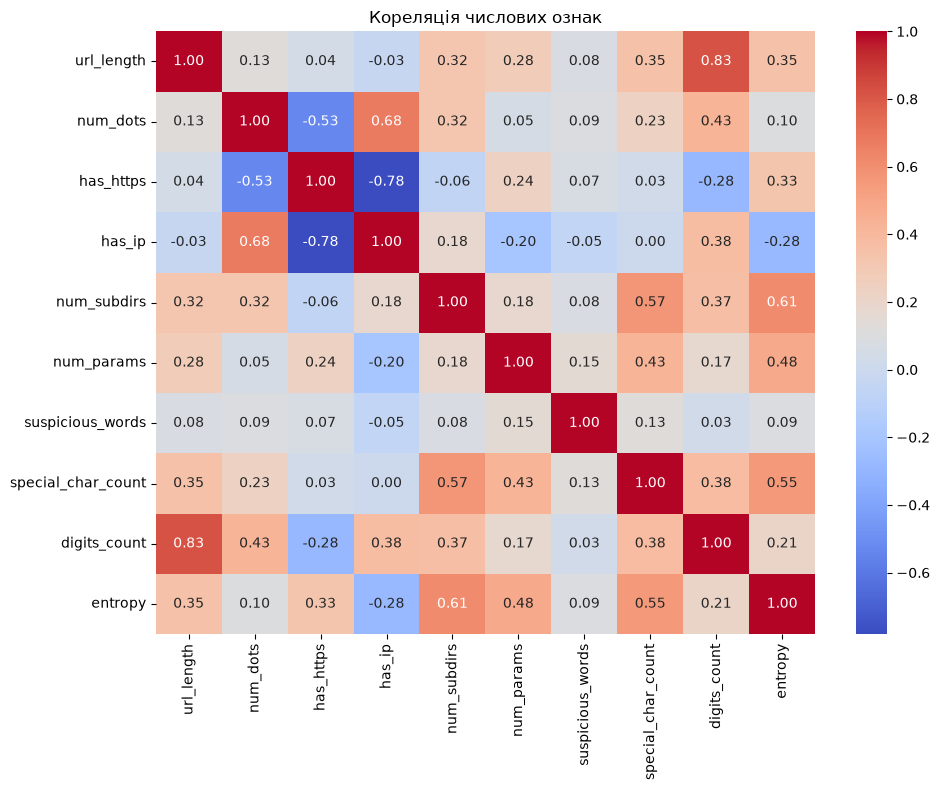

In [5]:
# (3)
import matplotlib.pyplot as plt
import seaborn as sns

correlation = df[feature_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Кореляція числових ознак")
plt.tight_layout()
plt.show()

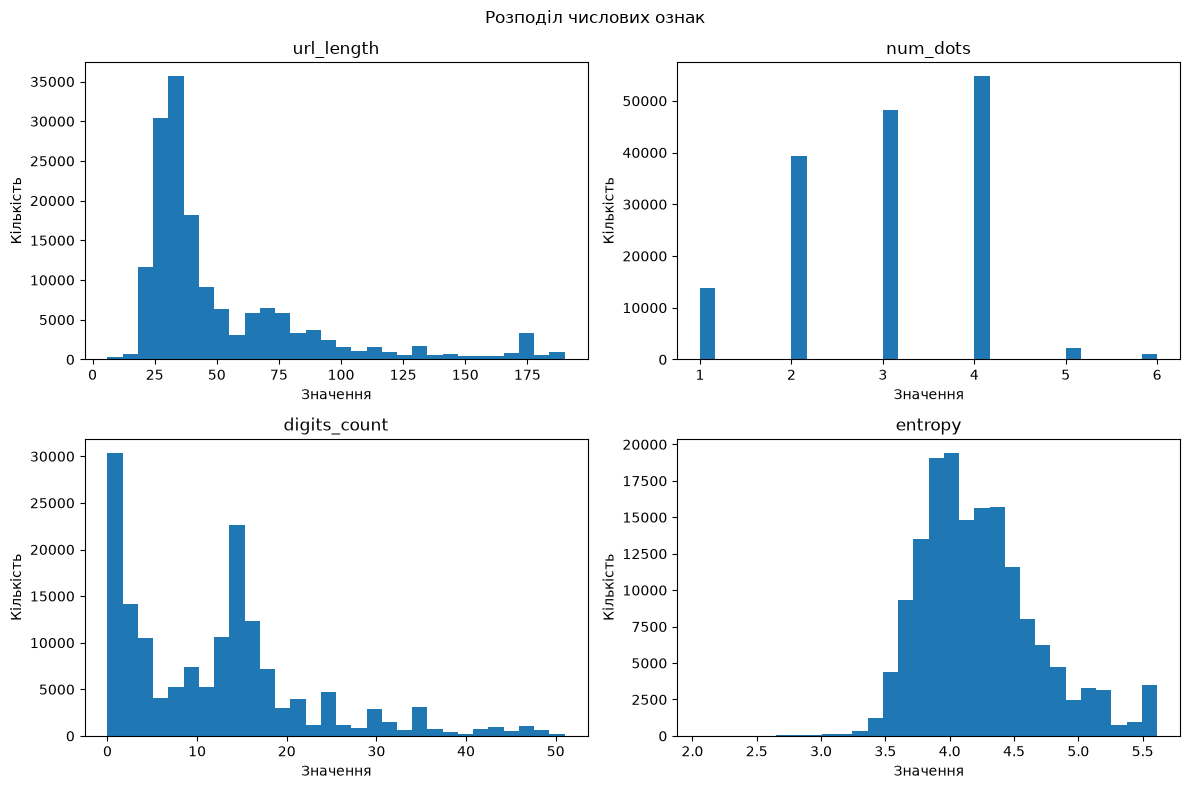

In [6]:
plot_cols = ["url_length", "num_dots", "digits_count", "entropy"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(plot_cols, axes.flat):
    limit = df[col].quantile(0.99)
    values = df.loc[df[col] <= limit, col]
    ax.hist(values, bins=30)
    ax.set_title(col)
    ax.set_xlabel("Значення")
    ax.set_ylabel("Кількість")

plt.suptitle("Розподіл числових ознак")
plt.tight_layout()
plt.show()

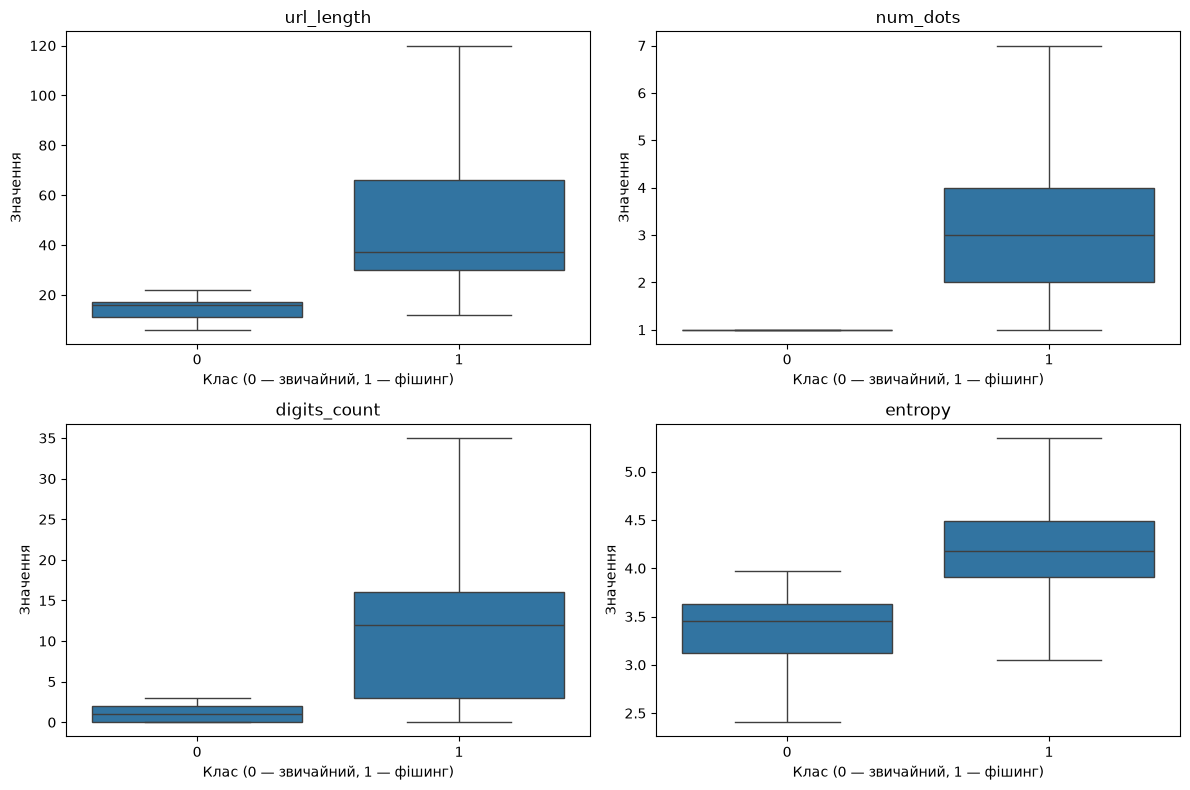

In [7]:
plot_cols = ["url_length", "num_dots", "digits_count", "entropy"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(plot_cols, axes.flat):
    sns.boxplot(data=df, x="label", y=col, showfliers=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Клас (0 — звичайний, 1 — фішинг)")
    ax.set_ylabel("Значення")

plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

print("\nКласи в навчальній вибірці:")
print(y_train.value_counts().sort_index())

print("\nКласи в тестовій вибірці:")
print(y_test.value_counts().sort_index())

Навчальна вибірка: (128051, 10)
Тестова вибірка: (32013, 10)

Класи в навчальній вибірці:
label
0       656
1    127395
Name: count, dtype: int64

Класи в тестовій вибірці:
label
0      164
1    31849
Name: count, dtype: int64


In [9]:
train_df = X_train.copy()
train_df[target_col] = y_train

class_0 = train_df[train_df[target_col] == 0]
class_1 = train_df[train_df[target_col] == 1].sample(
    n=len(class_0), random_state=42
)

balanced_train = pd.concat([class_0, class_1]).sample(
    frac=1, random_state=42
)

X_train_bal = balanced_train[feature_cols]
y_train_bal = balanced_train[target_col]

print("Класи в навчальних даних для моделей:")
print(y_train_bal.value_counts().sort_index())

Класи в навчальних даних для моделей:
label
0    656
1    656
Name: count, dtype: int64


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_bal_scaled = scaler.fit_transform(X_train_bal)
X_test_scaled = scaler.transform(X_test)

print("Розмір масштабованої навчальної вибірки:", X_train_bal_scaled.shape)
print("Розмір масштабованої тестової вибірки:", X_test_scaled.shape)

Розмір масштабованої навчальної вибірки: (1312, 10)
Розмір масштабованої тестової вибірки: (32013, 10)


In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

models = {
    "kNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "SVM": SVC(kernel="rbf"),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

for name, model in models.items():
    if name in ["kNN", "SVM"]:
        model.fit(X_train_bal_scaled, y_train_bal)
    else:
        model.fit(X_train_bal, y_train_bal)

    print(name, "— модель навчено")

kNN — модель навчено
Decision Tree — модель навчено
SVM — модель навчено
Random Forest — модель навчено
AdaBoost — модель навчено


In [12]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_search = GridSearchCV(
    estimator=make_pipeline(StandardScaler(), KNeighborsClassifier()),
    param_grid={"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21]},
    scoring="f1_macro",
    cv=cv
)

knn_search.fit(X_train_bal, y_train_bal)

print("Найкраще число сусідів:", knn_search.best_params_["kneighborsclassifier__n_neighbors"])
print("Середній F1 macro:", knn_search.best_score_)

models["kNN"] = knn_search.best_estimator_

Найкраще число сусідів: 1
Середній F1 macro: 1.0


In [13]:
svm_search = GridSearchCV(
    estimator=make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    param_grid={
        "svc__C": [0.1, 1, 10, 100],
        "svc__gamma": [0.001, 0.01, 0.1, 1]
    },
    scoring="f1_macro",
    cv=cv
)

svm_search.fit(X_train_bal, y_train_bal)

print("Найкращі параметри SVM:", svm_search.best_params_)
print("Середній F1 macro:", svm_search.best_score_)

models["SVM"] = svm_search.best_estimator_

Найкращі параметри SVM: {'svc__C': 0.1, 'svc__gamma': 1}
Середній F1 macro: 1.0


In [14]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    print("\nМодель:", name)
    print("Звіт класифікації:")
    print(classification_report(y_test, y_pred, labels=[0, 1],
                                digits=3, zero_division=0))

    print("Матриця помилок (рядки — справжній клас, стовпці — прогноз):")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

    results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 macro": f1_score(y_test, y_pred, average="macro"),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values(
    by=["F1 macro", "Balanced accuracy"], ascending=False
)

print("\nПорівняння моделей:")
print(results_df.to_string(index=False))


Модель: kNN
Звіт класифікації:
              precision    recall  f1-score   support

           0      1.000     0.982     0.991       164
           1      1.000     1.000     1.000     31849

    accuracy                          1.000     32013
   macro avg      1.000     0.991     0.995     32013
weighted avg      1.000     1.000     1.000     32013

Матриця помилок (рядки — справжній клас, стовпці — прогноз):
[[  161     3]
 [    0 31849]]

Модель: Decision Tree
Звіт класифікації:
              precision    recall  f1-score   support

           0      1.000     1.000     1.000       164
           1      1.000     1.000     1.000     31849

    accuracy                          1.000     32013
   macro avg      1.000     1.000     1.000     32013
weighted avg      1.000     1.000     1.000     32013

Матриця помилок (рядки — справжній клас, стовпці — прогноз):
[[  164     0]
 [    0 31849]]

Модель: SVM
Звіт класифікації:
              precision    recall  f1-score   support

 

In [15]:
# Найкращий результат на тестовій вибірці показали Decision Tree та AdaBoost: обидві моделі правильно класифікували всі 32 013 об’єктів,
# їхній F1 macro дорівнює 1,0. kNN і SVM зробили по 3 помилки, Random Forest - 19. Для цього датасета можна обрати Decision Tree: воно 
# досягло такого самого результату, як AdaBoost, а його правила класифікації простіше пояснити. Ідеальний результат слід трактувати 
# обережно: у цьому наборі звичайні та фішингові URL помітно відрізняються за числовими ознаками, тому це не доводить, що модель так само 
# працюватиме з новими URL з інших джерел